**Advanced Machine Learning and MLOps: SuperKart**

**Problem Statement**

**Business Context**

A sales forecast predicts future sales revenue based on historical data, industry trends, and the status of the current sales pipeline. Businesses use the sales forecast to estimate weekly, monthly, quarterly, and annual sales totals. A company needs to make an accurate sales forecast as it adds value across an organization and helps the different verticals to chalk out their future course of action. Forecasting helps an organization plan its sales operations by region and provides valuable insights to the supply chain team regarding the procurement of goods and materials.
An accurate sales forecast process has many benefits, which include improved decision-making about the future and the reduction of sales pipeline and forecast risks. Moreover, it helps to reduce the time spent in planning territory coverage and establishes benchmarks that can be used to assess trends in the future.

**Objective**

They hired you as an MLOps Engineer, and your task is to build an automated MLOps pipeline with CI/CD to deliver accurate and reliable sales forecasts. The objective is to leverage historical sales data, industry trends, and the current pipeline status to predict weekly, monthly, quarterly, and annual revenues. By automating data ingestion, preprocessing, model training, evaluation, and deployment, the pipeline will ensure scalability, consistency, and minimal manual intervention. With CI/CD integration, forecasts will be continuously updated and seamlessly deployed, enabling different business verticals to plan sales operations by region, optimize supply chain procurement, reduce risks in sales pipelines, and establish benchmarks for future trend analysis. Ultimately, this solution will enhance decision-making, streamline planning efforts, and drive operational efficiency and business growth.

**Data Description**

The data contains the different attributes of the various products and stores.
- Product_Id: Unique identifier of each product, each identifier having two letters at the beginning, followed by a number
- Product_Weight: Weight of each product
- Product_Sugar_Content: Sugar content of each product, like low sugar, regular, and no sugar
- Product_Allocated_Area: Ratio of the allocated display area of each product to the total display area of all the products in a store
- Product_Type: Broad category for each product like meat, snack foods, hard drinks, dairy, canned, soft drinks, health and hygiene, baking goods, bread, breakfast, frozen foods, fruits and vegetables, household, seafood, starchy foods, others
- Product_MRP: Maximum retail price of each product
- Store_Id: Unique identifier of each store
- Store_Establishment_Year: Year in which the store was established
- Store_Size: Size of the store, depending on sq. feet, like high, medium, and low
- Store_Location_City_Type: Type of city in which the store is located, like Tier 1, Tier 2, and Tier 3. Tier 1 consists of cities where the standard of living is comparatively higher than that of its Tier 2 and Tier 3 counterparts
- Store_Type: Type of store depending on the products that are being sold there, like Departmental Store, Supermarket Type 1, Supermarket Type 2, and Food Mart
- Product_Store_Sales_Total: Total revenue generated by the sale of that particular product in that particular store

**Installing necessary libraries**

In [ ]:
!pip install -U datasets huggingface_hub

In [ ]:
!pip install mlflow

**Importing necessary libraries**

In [ ]:
from huggingface_hub import login, create_repo, whoami, HfApi, hf_hub_download
from datasets import load_dataset, Dataset, DatasetDict
import joblib
import os

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV

from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (
    BaggingRegressor,
    RandomForestRegressor,
    AdaBoostRegressor,
    GradientBoostingRegressor
)
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, root_mean_squared_error, r2_score

import mlflow
import mlflow.sklearn

**Data Registration**

Create a master folder and create a subfolder "data"



In [ ]:
#create a master folder and create a subfolder "data"
create_repo(
    "Stuti22/data",
    repo_type="dataset",
    exist_ok=True
)

RepoUrl('https://huggingface.co/datasets/Stuti22/data', endpoint='https://huggingface.co', repo_type='dataset', repo_id='Stuti22/data')

In [ ]:
#logging into hugging face hub
login()

In [ ]:
#verifying the authentication
print(whoami())

{'type': 'user', 'id': '66982529d723c35c0e8e98d6', 'name': 'Stuti22', 'fullname': 'Sharma', 'canPay': False, 'billingMode': 'prepaid', 'periodEnd': 1793491200, 'isPro': False, 'avatarUrl': '/avatars/5a040c5c4e8a0a035f85d5da56699b21.svg', 'orgs': [], 'auth': {'type': 'oauth', 'expiresAt': '2026-11-05T05:50:57.000Z'}}


Register the data on the Hugging Face dataset space

In [ ]:
#registering the data on the Hugging Face dataset space
dataset = load_dataset("csv", data_files="SuperKart.csv")
dataset.push_to_hub(
    "Stuti22/data"
)

Setting num_proc from 1 back to 1 for the train split to disable multiprocessing as it only contains one shard.


Uploading the dataset shards:   0%|          | 0/1 [00:00<?, ? shards/s]

Creating parquet from Arrow format:   0%|          | 0/1 [00:00<?, ?ba/s]

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  /tmp/tmp33ro4ul2.parquet    : 100%|##########|  214kB /  214kB            

Validating                    :           |   0%            

CommitInfo(commit_url='https://huggingface.co/datasets/Stuti22/data/commit/1b92b2fc290cf7733e4eca7da7aebfb4e2023d34', commit_message='Upload dataset', commit_description='', oid='1b92b2fc290cf7733e4eca7da7aebfb4e2023d34', pr_url=None, repo_url=RepoUrl('https://huggingface.co/datasets/Stuti22/data', endpoint='https://huggingface.co', repo_type='dataset', repo_id='Stuti22/data'), pr_revision=None, pr_num=None)

**Data Preparation**

Loading the dataset directly from the Hugging Face data space.

In [ ]:
#loading the dataset
dataset = load_dataset("Stuti22/data")
dataset

Generating train split:   0%|          | 0/8763 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['Product_Id', 'Product_Weight', 'Product_Sugar_Content', 'Product_Allocated_Area', 'Product_Type', 'Product_MRP', 'Store_Id', 'Store_Establishment_Year', 'Store_Size', 'Store_Location_City_Type', 'Store_Type', 'Product_Store_Sales_Total'],
        num_rows: 8763
    })
})

In [ ]:
print(dataset)

DatasetDict({
    train: Dataset({
        features: ['Product_Id', 'Product_Weight', 'Product_Sugar_Content', 'Product_Allocated_Area', 'Product_Type', 'Product_MRP', 'Store_Id', 'Store_Establishment_Year', 'Store_Size', 'Store_Location_City_Type', 'Store_Type', 'Product_Store_Sales_Total'],
        num_rows: 8763
    })
})


In [ ]:
#converting hugging face dataset into pandas
df= dataset['train'].to_pandas()
df.head()

,Product_Id,Product_Weight,Product_Sugar_Content,Product_Allocated_Area,Product_Type,Product_MRP,Store_Id,Store_Establishment_Year,Store_Size,Store_Location_City_Type,Store_Type,Product_Store_Sales_Total
0,FD6114,12.66,Low Sugar,0.027,Frozen Foods,117.08,OUT004,2009,Medium,Tier 2,Supermarket Type2,2842.40
1,FD7839,16.54,Low Sugar,0.144,Dairy,171.43,OUT003,1999,Medium,Tier 1,Departmental Store,4830.02
2,FD5075,14.28,Regular,0.031,Canned,162.08,OUT001,1987,High,Tier 2,Supermarket Type1,4130.16
3,FD8233,12.10,Low Sugar,0.112,Baking Goods,186.31,OUT001,1987,High,Tier 2,Supermarket Type1,4132.18
4,NC1180,9.57,No Sugar,0.010,Health and Hygiene,123.67,OUT002,1998,Small,Tier 3,Food Mart,2279.36


Performing data cleaning and removing any unnecessary columns.

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8763 entries, 0 to 8762
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Product_Id                 8763 non-null   object 
 1   Product_Weight             8763 non-null   float64
 2   Product_Sugar_Content      8763 non-null   object 
 3   Product_Allocated_Area     8763 non-null   float64
 4   Product_Type               8763 non-null   object 
 5   Product_MRP                8763 non-null   float64
 6   Store_Id                   8763 non-null   object 
 7   Store_Establishment_Year   8763 non-null   int64  
 8   Store_Size                 8763 non-null   object 
 9   Store_Location_City_Type   8763 non-null   object 
 10  Store_Type                 8763 non-null   object 
 11  Product_Store_Sales_Total  8763 non-null   float64
dtypes: float64(4), int64(1), object(7)
memory usage: 821.7+ KB


In [ ]:
df['Store_Establishment_Year']= df['Store_Establishment_Year'].astype('object')

In [ ]:
df= df.drop('Product_Id', axis= 1)

In [ ]:
df= pd.get_dummies(df, drop_first= True).astype('float')
df.head()

,Product_Weight,Product_Allocated_Area,Product_MRP,Product_Store_Sales_Total,Product_Sugar_Content_No Sugar,Product_Sugar_Content_Regular,Product_Sugar_Content_reg,Product_Type_Breads,Product_Type_Breakfast,Product_Type_Canned,...,Store_Establishment_Year_1998,Store_Establishment_Year_1999,Store_Establishment_Year_2009,Store_Size_Medium,Store_Size_Small,Store_Location_City_Type_Tier 2,Store_Location_City_Type_Tier 3,Store_Type_Food Mart,Store_Type_Supermarket Type1,Store_Type_Supermarket Type2
0,12.66,0.027,117.08,2842.40,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0
1,16.54,0.144,171.43,4830.02,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
2,14.28,0.031,162.08,4130.16,0.0,1.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
3,12.10,0.112,186.31,4132.18,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
4,9.57,0.010,123.67,2279.36,1.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0


Splitting the cleaned dataset into training and testing sets, and saving them locally.

In [ ]:
#splitting the data into train and test sets
train_df, test_df= train_test_split(
   df, test_size=0.2, random_state=1
)

Uploading the resulting train and test datasets back to the Hugging Face data space.

In [ ]:
#Converting pandas dataframes into hugging face dataset objects
train_dataset = Dataset.from_pandas(train_df, preserve_index=False)
test_dataset = Dataset.from_pandas(test_df, preserve_index=False)

In [ ]:
#combining both objects to dataset dictionary
dataset_split = DatasetDict({
    "train": train_dataset,
    "test": test_dataset
})

In [ ]:
#printing the dataset dictionary
dataset_split

DatasetDict({
    train: Dataset({
        features: ['Product_Weight', 'Product_Allocated_Area', 'Product_MRP', 'Product_Store_Sales_Total', 'Product_Sugar_Content_No Sugar', 'Product_Sugar_Content_Regular', 'Product_Sugar_Content_reg', 'Product_Type_Breads', 'Product_Type_Breakfast', 'Product_Type_Canned', 'Product_Type_Dairy', 'Product_Type_Frozen Foods', 'Product_Type_Fruits and Vegetables', 'Product_Type_Hard Drinks', 'Product_Type_Health and Hygiene', 'Product_Type_Household', 'Product_Type_Meat', 'Product_Type_Others', 'Product_Type_Seafood', 'Product_Type_Snack Foods', 'Product_Type_Soft Drinks', 'Product_Type_Starchy Foods', 'Store_Id_OUT002', 'Store_Id_OUT003', 'Store_Id_OUT004', 'Store_Establishment_Year_1998', 'Store_Establishment_Year_1999', 'Store_Establishment_Year_2009', 'Store_Size_Medium', 'Store_Size_Small', 'Store_Location_City_Type_Tier 2', 'Store_Location_City_Type_Tier 3', 'Store_Type_Food Mart', 'Store_Type_Supermarket Type1', 'Store_Type_Supermarket Type2'],
  

In [ ]:
#uploading the dataset to hugging face hub
dataset_split.push_to_hub("Stuti22/data")

Setting num_proc from 1 back to 1 for the train split to disable multiprocessing as it only contains one shard.


Uploading the dataset shards:   0%|          | 0/1 [00:00<?, ? shards/s]

Creating parquet from Arrow format:   0%|          | 0/1 [00:00<?, ?ba/s]

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  /tmp/tmp3qxhv0yx.parquet    : 100%|##########|  151kB /  151kB            

... (5 outputs left out)

New Data Upload               : |          |  0.00B /  0.00B            

  /tmp/tmpvfi6j8rh.parquet    : 100%|##########| 55.6kB / 55.6kB            

Validating                    :           |   0%            

CommitInfo(commit_url='https://huggingface.co/datasets/Stuti22/data/commit/47bf93fc1bd919fefef1eab918d8e132f3a852e4', commit_message='Upload dataset', commit_description='', oid='47bf93fc1bd919fefef1eab918d8e132f3a852e4', pr_url=None, repo_url=RepoUrl('https://huggingface.co/datasets/Stuti22/data', endpoint='https://huggingface.co', repo_type='dataset', repo_id='Stuti22/data'), pr_revision=None, pr_num=None)

**Model Training and Registration**

Loading the train and test data from the Hugging Face data space

In [ ]:
from datasets import load_dataset

#loading data from hugging face
dataset = load_dataset("Stuti22/data")

#getting train and test
train_dataset = dataset["train"]
test_dataset = dataset["test"]

#converting to pandas
train_df = train_dataset.to_pandas()
test_df = test_dataset.to_pandas()

#Checking the shape of the dataset loaded
print("Train shape:", train_df.shape)
print("Test shape:", test_df.shape)

Generating train split:   0%|          | 0/7010 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1753 [00:00<?, ? examples/s]

Train shape: (7010, 35)
Test shape: (1753, 35)


In [ ]:
#printing the first five rows of train set
train_df.head()

,Product_Weight,Product_Allocated_Area,Product_MRP,Product_Store_Sales_Total,Product_Sugar_Content_No Sugar,Product_Sugar_Content_Regular,Product_Sugar_Content_reg,Product_Type_Breads,Product_Type_Breakfast,Product_Type_Canned,...,Store_Establishment_Year_1998,Store_Establishment_Year_1999,Store_Establishment_Year_2009,Store_Size_Medium,Store_Size_Small,Store_Location_City_Type_Tier 2,Store_Location_City_Type_Tier 3,Store_Type_Food Mart,Store_Type_Supermarket Type1,Store_Type_Supermarket Type2
0,11.68,0.044,141.82,3126.36,0.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0
1,11.81,0.100,180.62,3950.16,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0
2,13.23,0.061,127.23,3177.67,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0
3,15.51,0.073,170.86,4585.58,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
4,11.71,0.085,151.65,3333.79,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0


In [ ]:
#printing the first five rows of test set
test_df.head()

,Product_Weight,Product_Allocated_Area,Product_MRP,Product_Store_Sales_Total,Product_Sugar_Content_No Sugar,Product_Sugar_Content_Regular,Product_Sugar_Content_reg,Product_Type_Breads,Product_Type_Breakfast,Product_Type_Canned,...,Store_Establishment_Year_1998,Store_Establishment_Year_1999,Store_Establishment_Year_2009,Store_Size_Medium,Store_Size_Small,Store_Location_City_Type_Tier 2,Store_Location_City_Type_Tier 3,Store_Type_Food Mart,Store_Type_Supermarket Type1,Store_Type_Supermarket Type2
0,12.76,0.035,158.59,3714.07,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0
1,17.54,0.012,217.37,5995.91,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
2,12.02,0.013,201.24,4419.17,0.0,1.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
3,10.96,0.073,165.12,3440.23,0.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0
4,13.32,0.076,175.00,4175.82,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0


In [ ]:
#storing the predictor and target variable separately
X= train_df.drop(['Product_Store_Sales_Total'], axis= 1)
y= train_df['Product_Store_Sales_Total']

In [ ]:
#splitting predictors and target variable into train and test dataset
X_train, X_test, y_train, y_test= train_test_split(X, y, test_size= 0.2, random_state= 42)

In [ ]:
print(X_train.shape)
print(y_train.shape)
print(X_test.shape)
print(y_test.shape)

(5608, 34)
(5608,)
(1402, 34)
(1402,)


Defining a model and its parameters  

In [ ]:
#defining various models
models = {

    "Decision Tree": DecisionTreeRegressor(
        random_state=42
    ),

    "Bagging": BaggingRegressor(
        estimator=DecisionTreeRegressor(max_depth=10),
        random_state=42,
        n_jobs=-1
    ),

    "Random Forest": RandomForestRegressor(
        random_state=42,
        n_jobs=-1
    ),

    "AdaBoost": AdaBoostRegressor(
        estimator=DecisionTreeRegressor(max_depth=3),
        random_state=42
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        random_state=42
    ),

    "XGBoost": XGBRegressor(
        random_state=42
    )
}

Tuning the model with the defined parameters

In [ ]:
# defining parameters to be passed in GridSearch CV

param_grids = {

    "Decision Tree": {
        "max_depth": [3, 5, 10, None],
        "min_samples_split": [2, 5],
        "min_samples_leaf": [1, 2]
    },

    "Bagging": {
        "n_estimators": [50, 100],
        "max_samples": [0.5, 1.0],
        "max_features": [0.5, 1.0]
    },

    "Random Forest": {
        "n_estimators": [100],
        "max_depth": [None, 5, 10],
        "min_samples_split": [2, 5],
        "min_samples_leaf": [1, 2]
    },

    "AdaBoost": {
        "n_estimators": [50, 100],
        "learning_rate": [0.01, 0.1]
    },

    "Gradient Boosting": {
        "n_estimators": [50, 100],
        "learning_rate": [0.01, 0.05],
        "max_depth": [3, 5],
        "min_samples_split": [2, 5]
    },

    "XGBoost": {
        "n_estimators": [50, 100],
        "learning_rate": [0.01, 0.05],
        "max_depth": [3, 5]
    }
}

In [ ]:
# Tuning the models using GridSearchCV

tuned_models = {}
tuning_results = []

for model_name in models:

    print(f"Tuning {model_name}...")

    grid_search = GridSearchCV(
        estimator=models[model_name],
        param_grid=param_grids[model_name],
        cv=5,
        scoring="neg_root_mean_squared_error",
        n_jobs=-1
    )

    grid_search.fit(X_train, y_train)

    # Store the best model
    tuned_models[model_name] = grid_search.best_estimator_

    # Store tuning results
    tuning_results.append({
        "Model": model_name,
        "Best Parameters": grid_search.best_params_,
        "CV RMSE Score": -grid_search.best_score_
    })

    print(f"Best Parameters: {grid_search.best_params_}")
    print(f"CV RMSE: {-grid_search.best_score_:.4f}")
    print()

Tuning Decision Tree...
Best Parameters: {'max_depth': 10, 'min_samples_leaf': 2, 'min_samples_split': 5}
CV RMSE: 322.9084

Tuning Bagging...
Best Parameters: {'max_features': 1.0, 'max_samples': 0.5, 'n_estimators': 100}
CV RMSE: 279.8585

Tuning Random Forest...
Best Parameters: {'max_depth': None, 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 100}
CV RMSE: 276.2907

Tuning AdaBoost...
Best Parameters: {'learning_rate': 0.01, 'n_estimators': 50}
CV RMSE: 469.2063

Tuning Gradient Boosting...
Best Parameters: {'learning_rate': 0.05, 'max_depth': 5, 'min_samples_split': 2, 'n_estimators': 100}
CV RMSE: 288.7505

Tuning XGBoost...
Best Parameters: {'learning_rate': 0.05, 'max_depth': 5, 'n_estimators': 100}
CV RMSE: 291.4405



Tracking the tuned models with MLFLow

In [ ]:
# Logging the best parameters using MLflow

for model_name in models:

    with mlflow.start_run(run_name=f"{model_name}_tuning"):

        mlflow.log_param("model_name", model_name)

        grid_search = GridSearchCV(
            estimator=models[model_name],
            param_grid=param_grids[model_name],
            cv=5,
            scoring="neg_root_mean_squared_error",
            n_jobs=-1
        )

        grid_search.fit(X_train, y_train)

        best_model = grid_search.best_estimator_

        y_pred = best_model.predict(X_test)

        # Calculate test metrics
        rmse = root_mean_squared_error(y_test, y_pred)
        mae = mean_absolute_error(y_test, y_pred)
        r2 = r2_score(y_test, y_pred)

        # Log best parameters
        mlflow.log_params(grid_search.best_params_)

        # Log CV score
        mlflow.log_metric(
            "cv_rmse",
            -grid_search.best_score_
        )

        # Log test metrics
        mlflow.log_metric("test_rmse", rmse)
        mlflow.log_metric("test_mae", mae)
        mlflow.log_metric("test_r2", r2)

        # Log best model
        mlflow.sklearn.log_model(
            sk_model=best_model,
            artifact_path="model",
            serialization_format="skops",
            skops_trusted_types=["sklearn.tree._tree.Tree", 'xgboost.core.Booster', 'xgboost.sklearn.XGBRegressor']
)

        # Store best model
        tuned_models[model_name] = best_model

2026/10/06 07:15:48 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/10/06 07:16:34 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/10/06 07:18:16 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/10/06 07:18:37 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/10/06 07:19:36 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/10/06 07:19:46 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


Logging all the tuned parameters

In [ ]:
#storing the results as a dataframe
tuning_results_df = pd.DataFrame(tuning_results)

tuning_results_df

,Model,Best Parameters,CV RMSE Score
0,Decision Tree,"{'max_depth': 10, 'min_samples_leaf': 2, 'min_...",322.908352
1,Bagging,"{'max_features': 1.0, 'max_samples': 0.5, 'n_e...",279.858512
2,Random Forest,"{'max_depth': None, 'min_samples_leaf': 2, 'mi...",276.290735
3,AdaBoost,"{'learning_rate': 0.01, 'n_estimators': 50}",469.206301
4,Gradient Boosting,"{'learning_rate': 0.05, 'max_depth': 5, 'min_s...",288.750539
5,XGBoost,"{'learning_rate': 0.05, 'max_depth': 5, 'n_est...",291.440477


Evaluating the model performance

Choice of metric: RMSE

Root Mean Squared Error (RMSE) is selected as the primary evaluation metric because the objective of the project is to predict sales/revenue as accurately as possible. RMSE measures the magnitude of prediction errors in the same units as the target variable and places greater emphasis on larger errors due to the squaring of residuals. This is particularly relevant for revenue forecasting, where a large forecasting error can have a greater business impact on procurement, sales planning, inventory management, and financial decisions.

MAE and R² are used as supporting metrics. MAE provides an easy-to-interpret measure of the average absolute prediction error, while R² indicates the proportion of variation in revenue explained by the model. Using all three metrics provides a more comprehensive assessment of model performance.


In [ ]:
#sorting the model results by RMSE
tuning_results_df.sort_values(
    by="CV RMSE Score"
)

,Model,Best Parameters,CV RMSE Score
2,Random Forest,"{'max_depth': None, 'min_samples_leaf': 2, 'mi...",276.290735
1,Bagging,"{'max_features': 1.0, 'max_samples': 0.5, 'n_e...",279.858512
4,Gradient Boosting,"{'learning_rate': 0.05, 'max_depth': 5, 'min_s...",288.750539
5,XGBoost,"{'learning_rate': 0.05, 'max_depth': 5, 'n_est...",291.440477
0,Decision Tree,"{'max_depth': 10, 'min_samples_leaf': 2, 'min_...",322.908352
3,AdaBoost,"{'learning_rate': 0.01, 'n_estimators': 50}",469.206301


In [ ]:
#storing the best model and its name
best_model_name = tuning_results_df.loc[
    tuning_results_df["CV RMSE Score"].idxmin(),
    "Model"
]

best_model = tuned_models[best_model_name]

print("Best Model:", best_model_name)
print(best_model)

Best Model: Random Forest
RandomForestRegressor(min_samples_leaf=2, min_samples_split=5, n_jobs=-1,
                      random_state=42)


Register the best model in the Hugging Face model hub

In [ ]:
#saving the model locally
import joblib

joblib.dump(
    best_model,
    "best_superkart_model.joblib"
)

['best_superkart_model.joblib']

In [ ]:
#verifying if the path exists
import os

print(os.path.exists("best_superkart_model.joblib"))

True


In [ ]:
#logging into hugging face
from huggingface_hub import login

login()

In [ ]:
#creating the repository on hugging face
api = HfApi()

api.create_repo(
    repo_id="Stuti22/superkart-model",
    repo_type="model",
    exist_ok=True
)

RepoUrl('https://huggingface.co/Stuti22/superkart-model', endpoint='https://huggingface.co', repo_type='model', repo_id='Stuti22/superkart-model')

In [ ]:
#uploading the model
api.upload_file(
    path_or_fileobj="best_superkart_model.joblib",
    path_in_repo="best_superkart_model.joblib",
    repo_id="Stuti22/superkart-model",
    repo_type="model"
)

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  ...st_superkart_model.joblib:  88%|########7 | 16.0MB / 18.2MB            

Validating                    :           |   0%            

No files have been modified since last commit. Skipping to prevent empty commit.


CommitInfo(commit_url='https://huggingface.co/Stuti22/superkart-model/commit/aaf7669f99b849f1f86e326283088c93e1ccc577', commit_message='Upload best_superkart_model.joblib with huggingface_hub', commit_description='', oid='aaf7669f99b849f1f86e326283088c93e1ccc577', pr_url=None, repo_url=RepoUrl('https://huggingface.co/Stuti22/superkart-model', endpoint='https://huggingface.co', repo_type='model', repo_id='Stuti22/superkart-model'), pr_revision=None, pr_num=None)

**Model Deployment**

In [ ]:
#creating a deployment folder
os.makedirs("deployment", exist_ok=True)

Define a Dockerfile and list all configurations

In [ ]:
%%writefile deployment/Dockerfile

FROM python:3.11-slim

WORKDIR /app

COPY requirements.txt .

RUN pip install --no-cache-dir -r requirements.txt

COPY . .

EXPOSE 7860

CMD ["python", "app.py"]

Overwriting deployment/Dockerfile


Load the saved model from the Hugging Face model hub

In [ ]:
#loading the model from hugging face
model_path = hf_hub_download(
    repo_id="Stuti22/superkart-model",
    filename="best_superkart_model.joblib"
)
model = joblib.load(model_path)

In [ ]:
#checking the loaded model
print(model)

RandomForestRegressor(min_samples_leaf=2, min_samples_split=5, n_jobs=-1,
                      random_state=42)


In [ ]:
print(type(model))

<class 'sklearn.ensemble._forest.RandomForestRegressor'>


In [ ]:
#saving the loaded model from hugging space locally
joblib.dump(
    model,
    "deployment/model.joblib"
)

['deployment/model.joblib']

Get the inputs and save them into a dataframe

In [ ]:
# Get inputs from user

Product_Weight = float(input("Enter Product Weight: "))
Product_Sugar_Content = input("Enter Product Sugar Content: ")
Product_Allocated_Area = float(input("Enter Product Allocated Area: "))
Product_Type = input("Enter Product Type: ")
Product_MRP = float(input("Enter Product MRP: "))
Store_Id = input("Enter Store Id: ")
Store_Establishment_Year = int(input("Enter Store Establishment Year: "))
Store_Size = input("Enter Store Size: ")
Store_Location_City_Type = input("Enter Store Location City Type: ")
Store_Type = input("Enter Store Type: ")

Enter Product Weight: 20
Enter Product Sugar Content: Low Sugar
Enter Product Allocated Area: 0.22
Enter Product Type: Dairy
Enter Product MRP: 22
Enter Store Id: OUT004
Enter Store Establishment Year: 2009
Enter Store Size: 20
Enter Store Location City Type: Tier 1
Enter Store Type: Supermarket Type2


In [ ]:
# Save inputs into a dataframe

input_data = pd.DataFrame({
    "Product_Weight": [Product_Weight],
    "Product_Sugar_Content": [Product_Sugar_Content],
    "Product_Allocated_Area": [Product_Allocated_Area],
    "Product_Type": [Product_Type],
    "Product_MRP": [Product_MRP],
    "Store_Id": [Store_Id],
    "Store_Establishment_Year": [Store_Establishment_Year],
    "Store_Size": [Store_Size],
    "Store_Location_City_Type": [Store_Location_City_Type],
    "Store_Type": [Store_Type]
})

In [ ]:
print(input_data)

   Product_Weight Product_Sugar_Content  Product_Allocated_Area Product_Type  \
0            20.0             Low Sugar                    0.22        Dairy   

   Product_MRP Store_Id  Store_Establishment_Year Store_Size  \
0         22.0   OUT004                      2009         20   

  Store_Location_City_Type         Store_Type  
0                   Tier 1  Supermarket Type2  


Define a dependencies file for the deployment (requirements.txt)

In [ ]:
%%writefile deployment/requirements.txt

pandas
numpy
scikit-learn
xgboost
joblib
huggingface_hub
flask

Overwriting deployment/requirements.txt


Define a hosting script that can push all the deployment files into the Hugging Face space

In [ ]:
%%writefile deploy.py

from huggingface_hub import HfApi, login

SPACE_ID = "Stuti22/SuperKart_Project"
DEPLOYMENT_FOLDER = "deployment"

login()

api = HfApi()

api.upload_folder(
    folder_path=DEPLOYMENT_FOLDER,
    repo_id=SPACE_ID,
    repo_type="space",
    commit_message="Deploy superkart sales prediction application"
)

print("Deployment completed successfully!")

Overwriting deploy.py


**Automated Github Actions Workflow**

Create a pipeline.yml file in the GitHub repo

In [ ]:
#configuring git in colab
!git --version

git version 2.43.0


In [ ]:
!git config --global user.name "StutiSharma22"
!git config --global user.email "stutisharma1993@gmail.com"

In [ ]:
!git clone https://github.com/StutiSharma22/superkart_mlops.git

Cloning into 'superkart_mlops'...
remote: Enumerating objects: 18, done.
remote: Counting objects: 100% (18/18), done.
remote: Compressing objects: 100% (12/12), done.
remote: Total 18 (delta 2), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (18/18), 5.36 MiB | 14.25 MiB/s, done.
Resolving deltas: 100% (2/2), done.


In [ ]:
!mkdir -p .github/workflows

Define a YAML file and list all steps to execute each step of Machine Learning

Automate the end-to-end workflow

In [ ]:
%%writefile .github/workflows/pipeline.yml

name: SuperKart ML Pipeline

on:
  push:
    branches:
      - main

  pull_request:
    branches:
      - main

  workflow_dispatch:

jobs:

  build-and-test:

    runs-on: ubuntu-latest

    steps:

      - name: Checkout repository
        uses: actions/checkout@v4

      - name: Set up Python
        uses: actions/setup-python@v5
        with:
          python-version: "3.11"

      - name: Install dependencies
        run: |
          python -m pip install --upgrade pip
          pip install -r deployment/requirements.txt

      - name: Validate application
        run: |
          python -m py_compile deployment/app.py

      - name: Build Docker image
        run: |
          docker build -t superkart-ml deployment

Overwriting .github/workflows/pipeline.yml


Update the workflow to automatically push code updates to the main branch

Push all files to GitHub

In [ ]:
!git commit -m "Add superkart ML project and deployment files"

fatal: not a git repository (or any of the parent directories): .git


In [ ]:
!git remote -v
!git status

fatal: not a git repository (or any of the parent directories): .git
fatal: not a git repository (or any of the parent directories): .git


In [ ]:
!git push

fatal: not a git repository (or any of the parent directories): .git


In [ ]:
!zip -r /content/deployment.zip /content/deployment

updating: content/deployment/ (stored 0%)
updating: content/deployment/requirements.txt (deflated 6%)
updating: content/deployment/Dockerfile (deflated 16%)
updating: content/deployment/model.joblib (deflated 69%)


In [ ]:
from google.colab import files

files.download('/content/deployment.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**Output Evaluation**

GitHub (link to repository, screenshot of folder structure and executed workflow)

In [ ]:
"""https://github.com/StutiSharma22/superkart_mlops"""

'https://github.com/StutiSharma22/superkart_mlops'

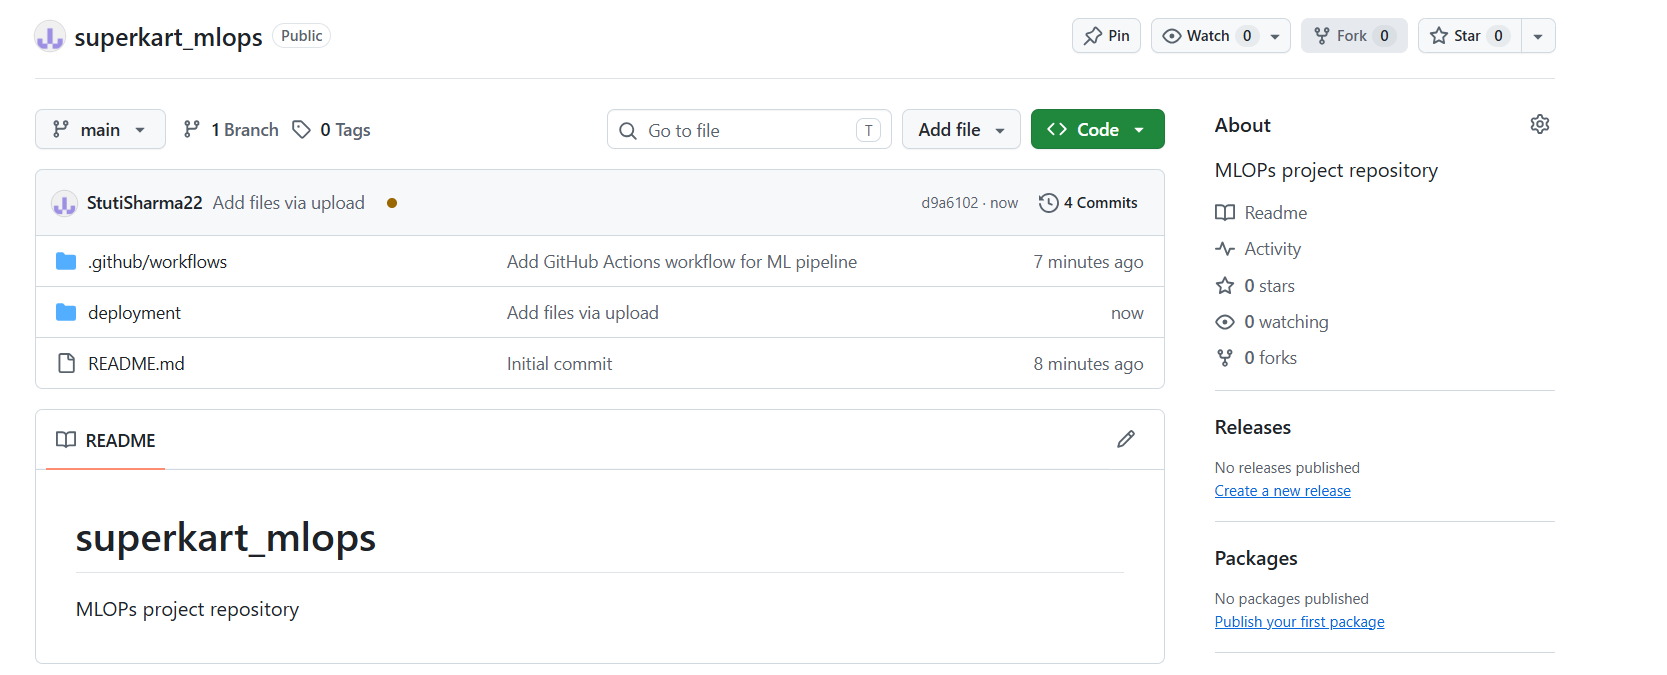

Streamlit on Hugging Face (link to HF space, screenshot of Streamlit app)

In [ ]:
"""https://huggingface.co/spaces/Stuti22/SuperKart"""

'https://huggingface.co/spaces/Stuti22/SuperKart'

**Actionable Insights and Recommendations**

Actionable Insights

The SuperKart prediction application uses the newly entered product and store parameters to predict the expected **Product Store Sales Total**. The prediction can help management estimate the potential revenue associated with a particular product-store combination and support operational planning.

Based on the new input parameters and predicted sales value, the following insights can be derived:

1. **Expected sales estimation**
   The predicted sales value provides an estimate of the revenue that may be generated by the selected product in the specified store. This can be used as an initial benchmark for sales planning.

2. **Product-level sales planning**
   Products with higher predicted sales can receive greater attention in inventory and promotional planning. Products with lower predicted sales can be reviewed to determine whether pricing, placement, product category, or demand-related factors require attention.

3. **Store-level planning**
   The store characteristics entered into the application, such as store size, location tier, establishment year, and store type, provide contextual information for interpreting the predicted sales.

4. **Impact of product price**
   The Product MRP is an important business parameter. The predicted sales estimate can be compared across different MRP values to understand how changes in pricing scenarios may affect expected sales.

5. **Display-area utilization**
   Product Allocated Area represents the proportion of store display space assigned to a product. Comparing predictions under different allocated-area values can help evaluate potential product-placement scenarios.

6. **Product category analysis**
   The prediction can be generated for different product types and sugar-content categories. This allows SuperKart to compare expected sales across different product characteristics.

7. **Scenario-based decision making**
   Managers can enter different combinations of product and store parameters and compare the resulting predictions. This enables "what-if" analysis before making inventory, pricing, product-placement, or store-planning decisions.

Recommendations

1. **Use predictions for inventory planning**
   Products with higher predicted sales can be considered when planning inventory levels and replenishment requirements, while avoiding excessive inventory for products with relatively lower predicted demand.

2. **Optimize product placement**
   SuperKart can experiment with different Product Allocated Area values in the prediction application to assess potential sales scenarios and support display-space allocation decisions.

3. **Support pricing decisions**
   Managers can test different Product MRP values and compare predicted sales. These predictions should be combined with actual sales, costs, margins, and competitive pricing before making pricing decisions.

4. **Develop store-specific strategies**
   Sales predictions can be analyzed across store types, store sizes, and location tiers to identify where particular products may have stronger sales potential.

5. **Focus promotional activities**
   Products with lower predicted sales can be investigated further to determine whether targeted promotions, improved placement, or other business interventions may be appropriate.

6. **Use what-if analysis before implementation**
   Before changing price, display allocation, or product strategy, managers can enter alternative parameter combinations into the application and compare the predicted sales outcomes.

7. **Continuously monitor prediction accuracy**
   Once actual sales become available, they should be compared with the model's predicted sales. This will help identify prediction errors and determine whether the model requires retraining.

8. **Retrain the model with new sales data**
   As SuperKart collects additional sales records, the new data should be incorporated into the MLOps pipeline. Periodic retraining and evaluation can help maintain model relevance as customer behavior and market conditions change.